# **IMPORT LIBRARIES**

In [1]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow  as tf
import torch
import numpy as np
from imblearn.over_sampling import SMOTE
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

# data loading

In [2]:
df = pd.read_csv("/content/drive/MyDrive/ict/adult_dataset.csv")

In [3]:
# Clean and map income immediately after loading the data
df["income"] = df["income"].astype(str).str.strip().str.strip(".")
df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})

# Verify right here that both 0 and 1 exist:
print(df["income"].value_counts())

income
0    37155
1    11687
Name: count, dtype: int64


In [4]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,0
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,0
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,0
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,0
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,0


In [5]:
# Datatypes
df.dtypes

,0
age,float64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object


In [6]:
# Shape of the data

df.shape

(48842, 15)

In [7]:
# Displaying last 5 rows

df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
48837,39.0,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36.0,United-States,0
48838,64.0,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40.0,United-States,0
48839,38.0,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50.0,United-States,0
48840,44.0,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40.0,United-States,0
48841,35.0,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60.0,United-States,1


In [8]:
# Checking missing values

df.isna().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [9]:
#to check the percentage of sum of missing values of each colunms

(df.isna().sum()/len(df))*100

,0
age,4.999795
workclass,6.883420
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,6.873183
relationship,0.000000
race,0.000000
sex,0.000000


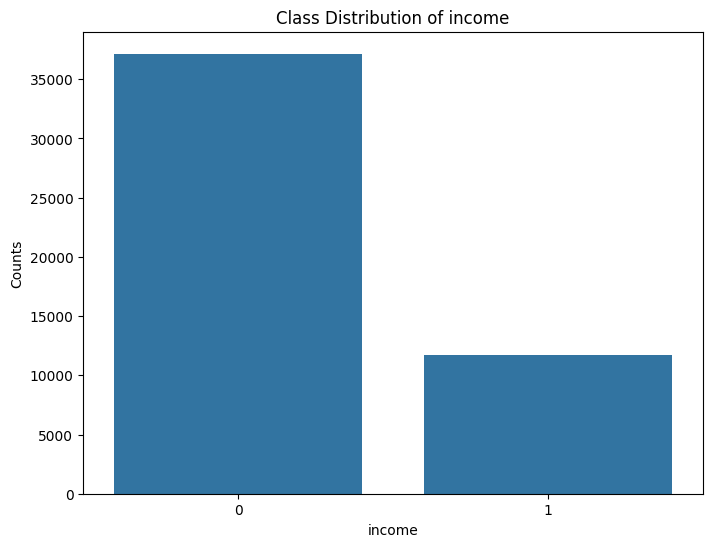

In [10]:
# Checking the class imbalance

values_grade = df['income'].value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=values_grade.index, y=values_grade.values)

plt.xlabel("income")
plt.ylabel("Counts")
plt.title("Class Distribution of income")
plt.show()

# TREATING MISSING VALUES

In [11]:
from sklearn.impute import KNNImputer

In [12]:
km =  KNNImputer(n_neighbors=5)

In [13]:
df_numerical = df.select_dtypes(exclude=["object"])


In [14]:
imdata = km.fit_transform(df_numerical)

In [15]:
imdata

array([[3.90000e+01, 7.75160e+04, 1.30000e+01, ..., 0.00000e+00,
        4.00000e+01, 0.00000e+00],
       [5.00000e+01, 8.33110e+04, 1.30000e+01, ..., 0.00000e+00,
        1.30000e+01, 0.00000e+00],
       [3.80000e+01, 2.15646e+05, 9.00000e+00, ..., 0.00000e+00,
        4.00000e+01, 0.00000e+00],
       ...,
       [3.80000e+01, 3.74983e+05, 1.30000e+01, ..., 0.00000e+00,
        5.00000e+01, 0.00000e+00],
       [4.40000e+01, 8.38910e+04, 1.30000e+01, ..., 0.00000e+00,
        4.00000e+01, 0.00000e+00],
       [3.50000e+01, 1.82148e+05, 1.30000e+01, ..., 0.00000e+00,
        6.00000e+01, 1.00000e+00]])

In [16]:
df_imdata = pd.DataFrame(data=imdata , columns=df_numerical.columns)

In [17]:
df_imdata.head(2)

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income
0,39.0,77516.0,13.0,2174.0,0.0,40.0,0.0
1,50.0,83311.0,13.0,0.0,0.0,13.0,0.0


In [18]:
# Put the imputed numerical columns back into the main dataframe
df[df_numerical.columns] = df_imdata

In [19]:
df_imdata.isna().sum()

,0
age,0
fnlwgt,0
education-num,0
capital-gain,0
capital-loss,0
hours-per-week,0
income,0


In [20]:
from sklearn.impute import SimpleImputer  # we use this for catagorical value

In [21]:
df_categories = df.select_dtypes(include=["object"])

In [22]:
sm =  SimpleImputer(strategy="most_frequent")

In [23]:
smdata = sm.fit_transform(df_categories)

In [24]:
smdata

array([['State-gov', 'Bachelors', 'Never-married', ..., 'White', 'Male',
        'United-States'],
       ['Self-emp-not-inc', 'Bachelors', 'Married-civ-spouse', ...,
        'White', 'Male', 'United-States'],
       ['Private', 'HS-grad', 'Divorced', ..., 'White', 'Male',
        'United-States'],
       ...,
       ['Private', 'Bachelors', 'Married-civ-spouse', ..., 'White',
        'Male', 'United-States'],
       ['Private', 'Bachelors', 'Divorced', ..., 'Asian-Pac-Islander',
        'Male', 'United-States'],
       ['Self-emp-inc', 'Bachelors', 'Married-civ-spouse', ..., 'White',
        'Male', 'United-States']], dtype=object)

In [25]:
df_smdata = pd.DataFrame(data=smdata, columns=df_categories.columns)

In [26]:
df_smdata.isna().sum()

,0
workclass,0
education,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0
native-country,0


In [27]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,NaN,0.0
1,50.0,Self-emp-not-inc,83311.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,0.0
2,38.0,Private,215646.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,0.0
3,53.0,Private,234721.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,0.0
4,28.0,Private,338409.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,0.0


In [28]:
target_data = df["income"]


# Extracting target data's name
target = target_data.name

# **FUTURE** **ENCODING**

In [29]:
# Handling encodings
df.drop(columns=["relationship"], inplace=True)
df.drop(columns=["race"], inplace=True)
df_categories = df.select_dtypes(include=["object"])

cat_cols = df_categories.columns



for col in cat_cols:
  print(f"{col} : {df[col].unique()}")

workclass : ['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' nan 'Local-gov'
 '?' 'Self-emp-inc' 'Without-pay' 'Never-worked']
education : ['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']
marital-status : ['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']
occupation : ['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' nan
 'Protective-serv' '?' 'Armed-Forces' 'Priv-house-serv']
sex : ['Male' 'Female']
native-country : [nan 'United-States' 'Cuba' 'Jamaica' 'India' '?' 'Mexico' 'South'
 'Puerto-Rico' 'Honduras' 'England' 'Germany' 'Iran' 'Philippines' 'Italy'
 'Columbia' 'Cambodia' 'Thailand' 'Canada' 'Ecuador' 'Laos' 'Taiwan'
 'Haiti' 'Portugal' 'Dominican-Republic

In [30]:
oh_encoding_cols = ['workclass','education','marital-status','occupation','native-country',
]

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

encoded_data = encoder.fit_transform(df[oh_encoding_cols])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(oh_encoding_cols),
    index=df.index
)

# Remove the original categorical columns
df = df.drop(columns=oh_encoding_cols)

# Combine encoded and numerical columns
df = pd.concat([df, encoded_df], axis=1)

In [31]:
lb_encoding_cols = [col for col in df_categories.columns if col not in oh_encoding_cols]
lb_encoding_cols

['sex']

In [32]:
le = LabelEncoder()

for col in lb_encoding_cols:
  df[col] = le.fit_transform(df[col].astype(str))

In [33]:
df.head()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,income,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,workclass_nan,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,occupation_nan,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,native-country_nan
0,39.0,77516.0,13.0,1,2174.0,0.0,40.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,50.0,83311.0,13.0,1,0.0,0.0,13.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,38.0,215646.0,9.0,1,0.0,0.0,40.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,53.0,234721.0,7.0,1,0.0,0.0,40.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,28.0,338409.0,13.0,0,0.0,0.0,40.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0

In [34]:
df.isna().sum()

,0
age,0
fnlwgt,0
education-num,0
sex,0
capital-gain,0
capital-loss,0
hours-per-week,0
income,0
workclass_Federal-gov,0
workclass_Local-gov,0


In [35]:
nan_cols = [col for col in df.columns if col.endswith("_nan")]
df = df.drop(columns=nan_cols)

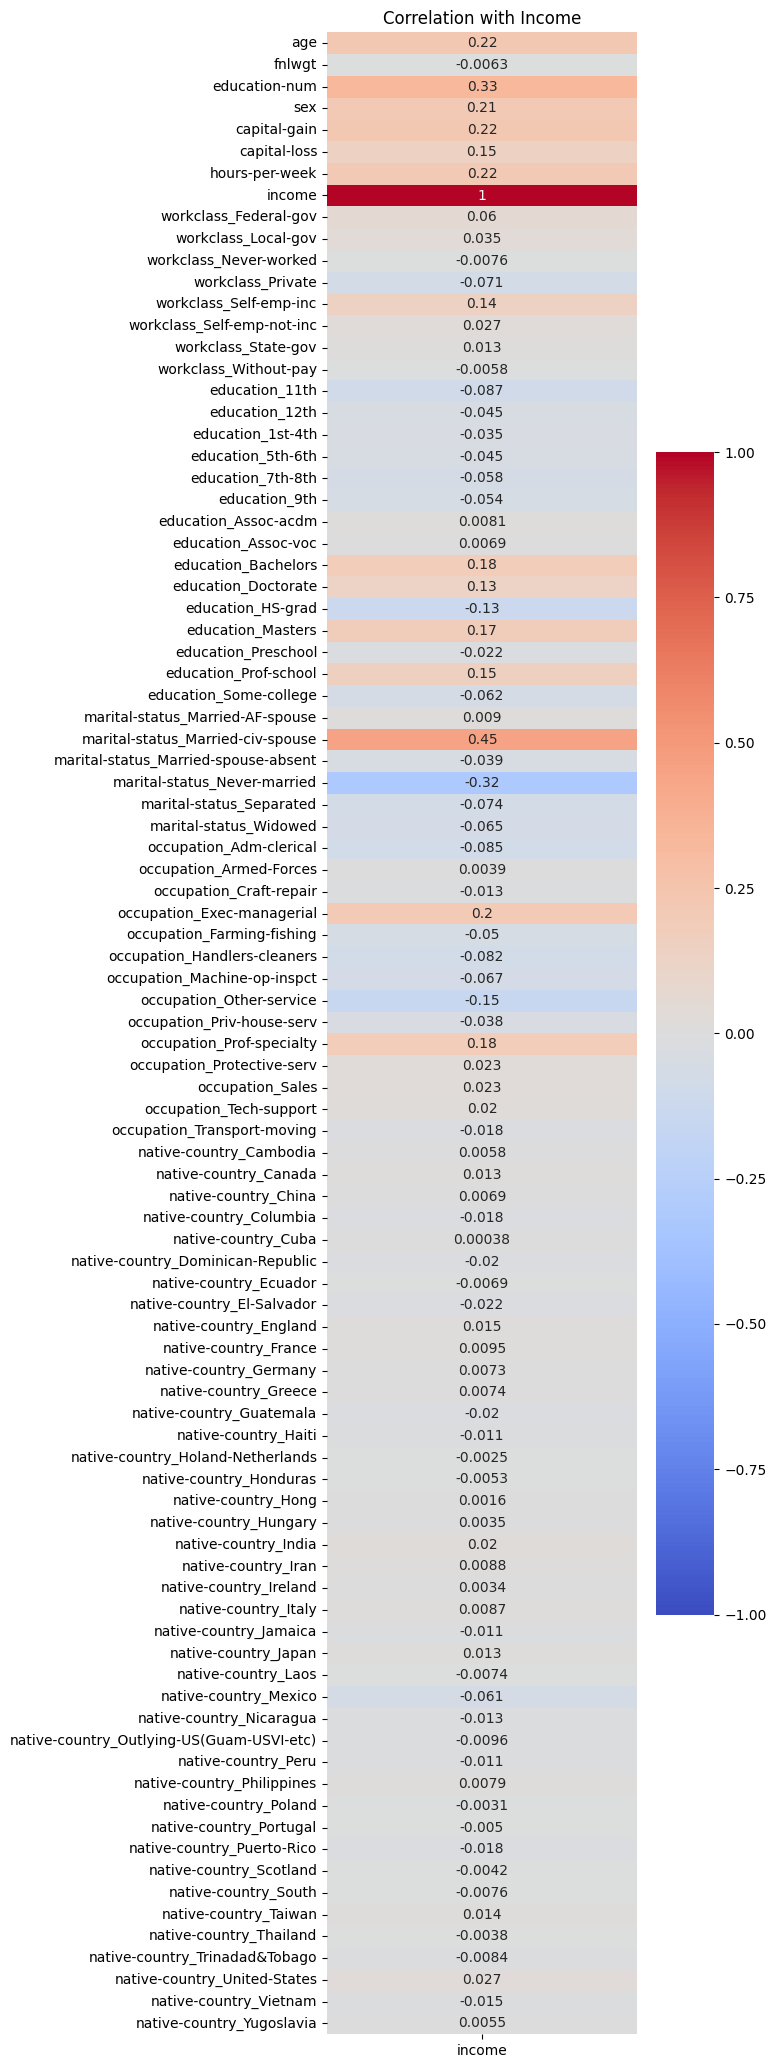

In [36]:
plt.figure(figsize=(5, 26))

target_corr = df.corr()[["income"]]

sns.heatmap(target_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation with Income")
plt.show()

Thresold value we select is 0.1

#Feature Engineering and Target Seperation

In [37]:
X = df.drop("income", axis=1)

y = df["income"]

In [38]:
X_train, X_test , y_train , y_test=train_test_split(X,y,train_size=0.8,random_state=42)

In [39]:
print(y_train.value_counts())

income
0.0    29741
1.0     9332
Name: count, dtype: int64


In [40]:
print(y_train.value_counts(normalize=True) * 100)

income
0.0    76.1165
1.0    23.8835
Name: proportion, dtype: float64


In [41]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# TENSOR FLOW

In [42]:
#
classifier = Sequential()

In [43]:
X_train_scaled.shape

(39073, 91)

In [44]:
# to create input variable
classifier.add(Dense(units=4))

In [45]:
# adding 1 hidden layer

classifier.add(Dense(units=12,activation="relu"))  # we can put any number of units in the hidden layer


In [46]:
# adding 2 hidden layer

classifier.add(Dense(units=15,activation="relu"))

In [47]:
# outputlayer

classifier.add(Dense(units=1,activation="sigmoid"))

In [48]:
from tensorflow.keras.callbacks import EarlyStopping

early_stoping = EarlyStopping(
    monitor="val_loss",
    min_delta=0,
    patience=0,
    verbose=0,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)

In [49]:
classifier.compile(
    optimizer = "adam",
    loss = "binary_crossentropy",
    metrics=["recall"],
)
model_history = classifier.fit(
    X_train_scaled,
    y_train,
    validation_split = 0.33,
    batch_size = 10,
    epochs = 1000,
    callbacks = [early_stoping]

)

Epoch 1/1000
2618/2618 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 0.3990 - recall: 0.3929 - val_loss: 0.3451 - val_recall: 0.5462
Epoch 2/1000
2618/2618 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.3319 - recall: 0.5910 - val_loss: 0.3318 - val_recall: 0.5544
Epoch 3/1000
2618/2618 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.3224 - recall: 0.5926 - val_loss: 0.3288 - val_recall: 0.5915
Epoch 4/1000
2618/2618 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.3191 - recall: 0.5974 - val_loss: 0.3271 - val_recall: 0.5478
Epoch 5/1000
2618/2618 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.3166 - recall: 0.5871 - val_loss: 0.3274 - val_recall: 0.5669


In [50]:
X_test.head()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
7762,18.0,423024.0,9.0,1,0.0,0.0,20.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
23881,17.0,178953.0,8.0,0,0.0,0.0,20.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
30507,25.0,348986.0,9.0,1,0.0,0.0,40.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
28911,20.0,218215.0,10.0,0,0.0,0.0,30.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
19484,30.0,244025.0,9.0,1,0.0,0.0,56.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## model test

In [51]:
new_data =np.array([[17.0,	178953.0,	8.0,	0,	0.0,	0.0,	20.0,	0.0,	0.0, 0.0,	1.0,	0.0,	0.0,	0.0,	0.0,	0.0,	1.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	1.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0, 0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	1.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	0.0,	1.0,	0.0,	0.0]])
#2. sacle
new_data_df = pd.DataFrame(new_data, columns=X.columns)
result = scaler.transform(new_data_df)
#3. predicted probability with trainer=d ann
predicted_prob = classifier.predict(result)[0][0]
#4. apply decsion threshold
threshold = 0.5
prediction = 1 if predicted_prob >= threshold else 0

print(f"predicted income probability : {predicted_prob:.4f}")
print(f"predicition : {'income(1)' if prediction == 1 else 'stay(0)' }")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 416ms/step
predicted income probability : 0.0018
predicition : stay(0)


In [52]:
# evalute

test_loss ,test_acc=classifier.evaluate(X_test_scaled,y_test)

print("Test accuracy ",test_acc)
print("Test Loss ",test_loss)

306/306 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3302 - recall: 0.5588
Test accuracy  0.5588110685348511
Test Loss  0.33021196722984314


In [53]:
from sklearn.metrics import accuracy_score, classification_report

In [54]:
# 1. Get binary predictions using 0.5 threshold
y_pred_probs = classifier.predict(X_test_scaled)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# 2. Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Classification Report:
              precision    recall  f1-score   support

         0.0       0.87      0.94      0.90      7414
         1.0       0.75      0.56      0.64      2355

    accuracy                           0.85      9769
   macro avg       0.81      0.75      0.77      9769
weighted avg       0.84      0.85      0.84      9769



#  py torch

In [55]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import accuracy_score, classification_report

In [56]:
# Create TensorDatasets for PyTorch
train_dataset = TensorDataset(
    torch.tensor(X_train_scaled, dtype=torch.float32),
    torch.tensor(y_train.values, dtype=torch.int64)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test.values, dtype=torch.int64)
)

In [57]:
# creating DataLoader

batch_size = 32
train_loader = DataLoader(
    train_dataset,
    batch_size = batch_size,
    shuffle = True
)
test_loader = DataLoader(
    test_dataset,
    batch_size = batch_size,
    shuffle =True
)

In [58]:
class Adult(nn.Module):
    def __init__(self, input_features, hidden1_size, hidden2_size, num_classes, dropout_rate):
        super().__init__()
        self.network = nn.Sequential(
            # 1st layer: takes 91 input features and outputs hidden1_size (64)
            nn.Linear(input_features, hidden1_size),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # 2nd layer: takes hidden1_size (64) and outputs hidden2_size (32)
            nn.Linear(hidden1_size, hidden2_size),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # 3rd layer: takes hidden2_size (32) and outputs num_classes (2)
            nn.Linear(hidden2_size, num_classes)
        )

    def forward(self, x):
        return self.network(x)

In [59]:
# get input features and number of class

input_features = X_test_scaled.shape[1]
num_classes = y_train.nunique()

print("input features :",input_features)
print("Number of classes :",num_classes)

input features : 91
Number of classes : 2


In [60]:
# create Model
model = Adult(
    input_features,
    num_classes=num_classes,
    hidden1_size=64,
    hidden2_size=32,
    dropout_rate=0.3
)

In [61]:
model

Adult(
  (network): Sequential(
    (0): Linear(in_features=91, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=2, bias=True)
  )
)

In [62]:
loss_function = nn.CrossEntropyLoss()

In [63]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)

In [64]:
# training

epochs= 100
for epoch in range(epochs):
  model.train()

  total_loss = 0

  for X_batch, y_batch in train_loader:
    #forward pass
    predictions = model (X_batch)

    #claculate loss
    loss = loss_function(
        predictions,
        y_batch
    )
    # stores the loss immediatley
    total_loss = total_loss + loss.item()

    # remove previous gradients
    optimizer.zero_grad()

    # backpropagation
    loss.backward()

    # update weights
    optimizer.step()

  average_loss = total_loss/len(train_loader)
  if(epoch + 1) % 10 ==0:

    print(
          f"Epoch [{epoch + 1}/{epochs}], "
          f"Loss : {average_loss:4f}"
      )

Epoch [10/100], Loss : 0.311386
Epoch [20/100], Loss : 0.303635
Epoch [30/100], Loss : 0.300398
Epoch [40/100], Loss : 0.296593
Epoch [50/100], Loss : 0.294029
Epoch [60/100], Loss : 0.293782
Epoch [70/100], Loss : 0.291160
Epoch [80/100], Loss : 0.290671
Epoch [90/100], Loss : 0.287849
Epoch [100/100], Loss : 0.290810


In [65]:
# Testing

model.eval()

all_actual = []
all_predictions = []

with torch.no_grad():

  for X_batch, y_batch in test_loader:

    # get predictions
    predictions = model(X_batch)

    # Get predicted class
    predicted_classes = torch.argmax(predictions, dim=1)

    # store actual and predicted classes
    all_actual.extend(y_batch.numpy())
    all_predictions.extend(predicted_classes.numpy())

In [66]:
# Evaluation

from sklearn.metrics import accuracy_score, classification_report

In [67]:
# Calculate accuray
accuracy = accuracy_score(all_actual, all_predictions)

print("ACCuracy : ",accuracy)

# Classificatio Report
print("\nClassification Report : ")
print(classification_report(all_actual, all_predictions))

ACCuracy :  0.8520831200737026

Classification Report : 
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7414
           1       0.75      0.58      0.65      2355

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.85      0.85      0.85      9769



# compare 2 models

In [68]:
# 1. Generate predictions for TensorFlow model
tf_pred_probs = classifier.predict(X_test_scaled)
tf_preds = (tf_pred_probs >= 0.5).astype(int).flatten()

# 2. Extract classification report dicts
tf_report = classification_report(y_test, tf_preds, output_dict=True)
torch_report = classification_report(all_actual, all_predictions, output_dict=True)

# 3. Create a comparison dataframe
comparison_df = pd.DataFrame({
    'TensorFlow': [
        tf_report['accuracy'],
        tf_report['0.0']['precision'], tf_report['0.0']['recall'], tf_report['0.0']['f1-score'],
        tf_report['1.0']['precision'], tf_report['1.0']['recall'], tf_report['1.0']['f1-score']
    ],
    'PyTorch': [
        torch_report['accuracy'],
        torch_report['0']['precision'], torch_report['0']['recall'], torch_report['0']['f1-score'],
        torch_report['1']['precision'], torch_report['1']['recall'], torch_report['1']['f1-score']
    ]
}, index=[
    'Accuracy',
    'Class 0 Precision', 'Class 0 Recall', 'Class 0 F1-Score',
    'Class 1 Precision', 'Class 1 Recall', 'Class 1 F1-Score'
])

print("--- Model Performance Comparison ---")
display(comparison_df.round(4))

306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
--- Model Performance Comparison ---


,TensorFlow,PyTorch
Accuracy,0.8497,0.8521
Class 0 Precision,0.8705,0.8754
Class 0 Recall,0.9421,0.9388
Class 0 F1-Score,0.9049,0.9060
Class 1 Precision,0.7542,0.7503
Class 1 Recall,0.5588,0.5792
Class 1 F1-Score,0.6420,0.6537


# Hyper parameter Tunning on pytorch

In [69]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


cm = confusion_matrix(
    all_actual,
    all_predictions
)

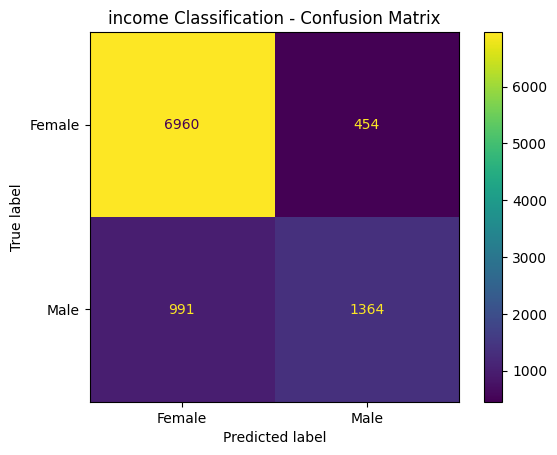

In [70]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels = le.classes_
)

disp.plot()

plt.title("income Classification - Confusion Matrix")
plt.show()

In [71]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 27.3 MB/s eta 0:00:00


In [72]:
import optuna
# hyperparameeter tunning requires validation dataset

X_train_split,X_val_split,y_train_split,y_val_split = train_test_split(
    X_train_scaled,y_train,
    test_size=0.2,
    random_state = 42,
    stratify=y_train
)

#2.

train_data = TensorDataset(
    torch.tensor(X_train_split,dtype = torch.float32),
    torch.tensor(y_train_split.values,dtype = torch.int64),
)
val_data=TensorDataset(
    torch.tensor(X_val_split,dtype=torch.float32),
    torch.tensor(y_val_split.values,dtype=torch.int64)
)
test_data = TensorDataset(
    torch.tensor(X_train_scaled,dtype=torch.float32),
    torch.tensor(y_train,dtype=torch.int64)
)
input_features = X_train_scaled.shape[1]
num_classes = len(le.classes_)

In [73]:
#create objective function for optma
def objective(trail):
  lr = trail.suggest_categorical("lr",[0.01,0.001,0.1])#learing rate
  batch_size = trail.suggest_categorical("batch_size",[16,32,64,128])#bah size
  hidden1 =  trail.suggest_categorical("hidden1",[32,64,128])# neuron in layer 1
  hidden2 =  trail.suggest_categorical("hidden2",[16,32,64])# neuron in layer 2
  dropout = trail.suggest_categorical("dropout", [0.0, 0.1, 0.2, 0.3])
  # Loading the train and validation dataset with optmized barch size value
  train_loader =  DataLoader(train_data,batch_size=batch_size,shuffle=False)
  val_loader = DataLoader(val_data,batch_size=batch_size,shuffle=False)

  #create model with optimized hidden layer values,learing rate and dropout
  model = Adult(input_features, hidden1, hidden2, num_classes, dropout)
  criterian = nn.CrossEntropyLoss()
  optimizer =  torch.optim.Adam(model.parameters(),lr=lr)

  # tunning the model

  epoch =20
  for epoch in range(epochs):
    model.train()
    for X_batch,y_batch in train_loader:
      optimizer.zero_grad()
      predictions = model(X_batch)# after predicition calculate loss
      loss = criterian(predictions,y_batch)
      loss.backward()
      optimizer.step()


  # calculate accuracy on validation data

  model.eval()
  val_predicitions= []
  val_actual = []


  with torch.no_grad():
    for X_batch,y_batch in  val_loader:
      preds = model(X_batch)
      predicted_classes =  torch.argmax(preds,dim=1)
      val_predicitions.extend(predicted_classes.numpy())
      val_actual.extend(y_batch.numpy())
  val_accuracy = accuracy_score(val_actual,val_predicitions)
  return val_accuracy



#do not slpit this columns into multiple cell

In [74]:
# passing the objective functions insifr yje option harder find lost paramtere

study= optuna.create_study(direction = "maximize")
study.optimize(objective,n_trials=20)
for key,value in study.best_params.items():
  print(f"{key}:{value}")

  print(f"\validation accuracy :{study.best_value:.4f}")

[I 2026-10-19 05:21:12,905] A new study created in memory with name: no-name-d9c3f9a3-7464-4954-938d-9b3cc269f5ec
[I 2026-10-19 05:22:58,431] Trial 0 finished with value: 0.8390275111964172 and parameters: {'lr': 0.001, 'batch_size': 64, 'hidden1': 32, 'hidden2': 64, 'dropout': 0.0}. Best is trial 0 with value: 0.8390275111964172.
[I 2026-10-19 05:24:51,641] Trial 1 finished with value: 0.8504158669225848 and parameters: {'lr': 0.01, 'batch_size': 64, 'hidden1': 128, 'hidden2': 16, 'dropout': 0.2}. Best is trial 1 with value: 0.8504158669225848.
[I 2026-10-19 05:27:55,863] Trial 2 finished with value: 0.7612284069097889 and parameters: {'lr': 0.1, 'batch_size': 32, 'hidden1': 64, 'hidden2': 32, 'dropout': 0.0}. Best is trial 1 with value: 0.8504158669225848.
[I 2026-10-19 05:34:52,678] Trial 3 finished with value: 0.7612284069097889 and parameters: {'lr': 0.1, 'batch_size': 16, 'hidden1': 128, 'hidden2': 32, 'dropout': 0.2}. Best is trial 1 with value: 0.8504158669225848.
[I 2026-10-19

lr:0.001
alidation accuracy :0.8548
batch_size:16
alidation accuracy :0.8548
hidden1:128
alidation accuracy :0.8548
hidden2:32
alidation accuracy :0.8548
dropout:0.3
alidation accuracy :0.8548


In [77]:
#Train the final model with best parameters
best = study.best_params

#Prepare full training and test dataloaders
full_train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train_scaled, dtype=torch.float32),
        torch.tensor(y_train.values, dtype=torch.int64)
    ),
    batch_size=best["batch_size"],
    shuffle=True
)

test_loader = DataLoader(test_data, batch_size=best["batch_size"], shuffle=False)

#Build model with best parameters
final_model = Adult(
    input_features=input_features,
    hidden1_size=best["hidden1"],
    hidden2_size=best["hidden2"],
    num_classes=num_classes,
    dropout_rate=best["dropout"]
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(final_model.parameters(), lr=best["lr"])

#Train final model for 50 epochs
epochs = 50
print("\nTraining final model...")
for epoch in range(epochs):
    final_model.train()
    for X_batch, y_batch in full_train_loader:
        optimizer.zero_grad()
        loss = criterion(final_model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

#Evaluate on Test Data
final_model.eval()
test_preds = []
test_actual = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        preds = final_model(X_batch)
        predicted_classes = torch.argmax(preds, dim=1)
        test_preds.extend(predicted_classes.numpy())
        test_actual.extend(y_batch.numpy())

#Final Results
print("\n FINAL TEST EVALUATION \n")
print("Test Accuracy:", accuracy_score(test_actual, test_preds))
print("\nClassification Report:")
print(classification_report(test_actual, test_preds))


Training final model...

 FINAL TEST EVALUATION 

Test Accuracy: 0.8773577662324368

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92     29741
           1       0.83      0.61      0.70      9332

    accuracy                           0.88     39073
   macro avg       0.86      0.78      0.81     39073
weighted avg       0.87      0.88      0.87     39073



#hyper tunning paramters for tensorflow

In [79]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 3.7 MB/s eta 0:00:00


In [80]:
import keras_tuner as kt

# 1. Define the model-building function with hyperparameters (hp)
def Adult_tf(hp):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(input_features,)))

    # Tune number of units in hidden layers
    model.add(tf.keras.layers.Dense(
        units=hp.Choice("hidden1", [32, 64, 128]),
        activation="relu"
    ))
    model.add(tf.keras.layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3])))

    model.add(tf.keras.layers.Dense(
        units=hp.Choice("hidden2", [16, 32, 64]),
        activation="relu"
    ))

    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    # Tune learning rate
    lr = hp.Choice("lr", [0.01, 0.001, 0.1])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# 2. Initialize the Tuner (using RandomSearch or Hyperband)
tuner = kt.RandomSearch(
    Adult_tf,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="keras_tuning",
    project_name="adult_income_tf",
    overwrite=True
)

# 3. Run the hyperparameter search
tuner.search(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32
)

# 4. Get the best hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Best hidden1 units: {best_hps.get('hidden1')}")
print(f"Best hidden2 units: {best_hps.get('hidden2')}")
print(f"Best dropout rate: {best_hps.get('dropout')}")
print(f"Best learning rate: {best_hps.get('lr')}")

# 5. Build and train the final model with best parameters
best_model = tuner.hypermodel.build(best_hps)
history = best_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32
)

Trial 10 Complete [00h 01m 06s]
val_accuracy: 0.7617402672767639

Best val_accuracy So Far: 0.8582213521003723
Total elapsed time: 00h 11m 35s
Best hidden1 units: 128
Best hidden2 units: 32
Best dropout rate: 0.3
Best learning rate: 0.001
Epoch 1/50
977/977 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8315 - loss: 0.3655 - val_accuracy: 0.8481 - val_loss: 0.3326
Epoch 2/50
977/977 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8481 - loss: 0.3301 - val_accuracy: 0.8544 - val_loss: 0.3254
Epoch 3/50
977/977 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8517 - loss: 0.3214 - val_accuracy: 0.8530 - val_loss: 0.3208
Epoch 4/50
977/977 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8534 - loss: 0.3158 - val_accuracy: 0.8562 - val_loss: 0.3179
Epoch 5/50
977/977 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8546 - loss: 0.3130 - val_accuracy: 0.8576 - val_loss: 0.3192
Epoch 6/50
977/977 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8571 - loss: 0.3112 - val_accuracy: 0.8562 - val_loss: 

In [81]:
# 1. Evaluate the best model on the test set
test_loss, test_accuracy = best_model.evaluate(X_test_scaled, y_test, verbose=0)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}\n")

# 2. Generate predictions for classification report
y_pred_probs = best_model.predict(X_test_scaled)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# 3. Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.8493
Test Loss: 0.3459

306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Classification Report:
              precision    recall  f1-score   support

         0.0       0.87      0.94      0.90      7414
         1.0       0.75      0.56      0.64      2355

    accuracy                           0.85      9769
   macro avg       0.81      0.75      0.77      9769
weighted avg       0.84      0.85      0.84      9769



In [82]:
# Create a comparison dataframe for PyTorch and TensorFlow
comparison_df = pd.DataFrame(
    {
        "TensorFlow": [
            tf_report["accuracy"],
            tf_report["0.0"]["precision"],
            tf_report["0.0"]["recall"],
            tf_report["0.0"]["f1-score"],
            tf_report["1.0"]["precision"],
            tf_report["1.0"]["recall"],
            tf_report["1.0"]["f1-score"],
        ],
        "PyTorch": [
            torch_report["accuracy"],
            torch_report["0"]["precision"],
            torch_report["0"]["recall"],
            torch_report["0"]["f1-score"],
            torch_report["1"]["precision"],
            torch_report["1"]["recall"],
            torch_report["1"]["f1-score"],
        ],
    },
    index=[
        "Accuracy",
        "Class 0 Precision",
        "Class 0 Recall",
        "Class 0 F1-Score",
        "Class 1 Precision",
        "Class 1 Recall",
        "Class 1 F1-Score",
    ],
)

print("--- Model Performance Comparison ---")
display(comparison_df.round(4))

--- Model Performance Comparison ---


,TensorFlow,PyTorch
Accuracy,0.8497,0.8521
Class 0 Precision,0.8705,0.8754
Class 0 Recall,0.9421,0.9388
Class 0 F1-Score,0.9049,0.9060
Class 1 Precision,0.7542,0.7503
Class 1 Recall,0.5588,0.5792
Class 1 F1-Score,0.6420,0.6537
